<a href="https://colab.research.google.com/github/minxuan0923/AML_Assignment/blob/yy/Set3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
!pip install ucimlrepo

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

In [11]:
dataset = fetch_ucirepo(id=327)

X = dataset.data.features.copy()
y = dataset.data.targets.iloc[:, 0].copy()

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

print("Class distribution:")
print(y.value_counts())

Feature shape: (11055, 30)
Target shape: (11055,)


,having_ip_address,url_length,shortining_service,having_at_symbol,double_slash_redirecting,prefix_suffix,having_sub_domain,sslfinal_state,domain_registration_length,favicon,...,rightclick,popupwindow,iframe,age_of_domain,dnsrecord,web_traffic,page_rank,google_index,links_pointing_to_page,statistical_report
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,1,-1,-1,-1,-1,1,1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,1,-1,-1,0,-1,1,1,1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,1,-1,1,-1,1,0,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,1,-1,-1,1,-1,1,-1,1
4,1,0,-1,1,1,-1,1,1,-1,1,...,1,-1,1,-1,-1,0,-1,1,1,1


Class distribution:
result
 1    6157
-1    4898
Name: count, dtype: int64


In [12]:
print("Missing values:", X.isnull().sum().sum())

print("Original labels:")
print(y.value_counts())

# Convert phishing into positive class
y = y.map({-1: 1, 1: 0})

print("Converted labels:")
print(y.value_counts())

Missing values: 0
Original labels:
result
 1    6157
-1    4898
Name: count, dtype: int64
Converted labels:
result
0    6157
1    4898
Name: count, dtype: int64


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape)
print("Testing samples:", X_test.shape)

Training samples: (8844, 30)
Testing samples: (2211, 30)


In [14]:
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=True
)

X_train_encoded = encoder.fit_transform(X_train)
X_test_encoded = encoder.transform(X_test)

print("Original features:", X_train.shape[1])
print("Encoded features:", X_train_encoded.shape[1])

Original features: 30
Encoded features: 68


In [15]:
interaction = PolynomialFeatures(
    degree=2,
    interaction_only=True,
    include_bias=False
)

X_train_interaction = interaction.fit_transform(
    X_train_encoded
)

X_test_interaction = interaction.transform(
    X_test_encoded
)

print("Before interaction:",
      X_train_encoded.shape[1])

print("After interaction:",
      X_train_interaction.shape[1])

Before interaction: 68
After interaction: 2346


In [16]:
model = LogisticRegression(
    C=1.0,
    penalty="l2",
    solver="lbfgs",
    max_iter=2000,
    random_state=42
)

model.fit(X_train_interaction, y_train)

print("Model training completed.")

Model training completed.


In [17]:
y_pred = model.predict(X_test_interaction)

y_prob = model.predict_proba(
    X_test_interaction
)[:, 1]

In [18]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

TN, FP, FN, TP = cm.ravel()

fnr = FN / (FN + TP)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {auc:.4f}")
print(f"FNR:       {fnr:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Legitimate", "Phishing"]
))

Accuracy:  0.9706
Precision: 0.9731
Recall:    0.9602
F1-score:  0.9666
ROC-AUC:   0.9956
FNR:       0.0398

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.97      0.98      0.97      1231
    Phishing       0.97      0.96      0.97       980

    accuracy                           0.97      2211
   macro avg       0.97      0.97      0.97      2211
weighted avg       0.97      0.97      0.97      2211



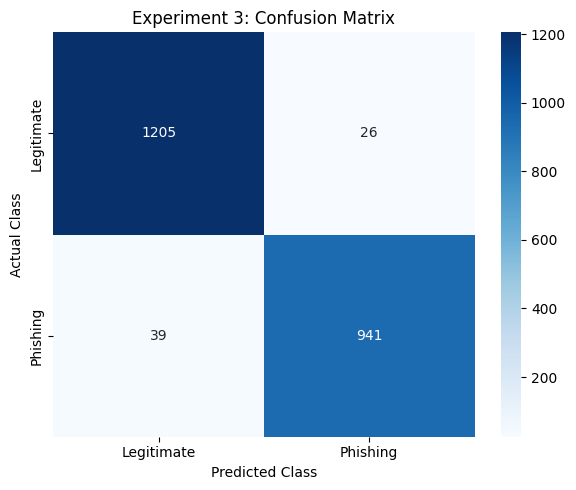

In [19]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Phishing"],
    yticklabels=["Legitimate", "Phishing"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Experiment 3: Confusion Matrix")

plt.tight_layout()
plt.savefig("Experiment3_Confusion_Matrix.png", dpi=300)
plt.show()

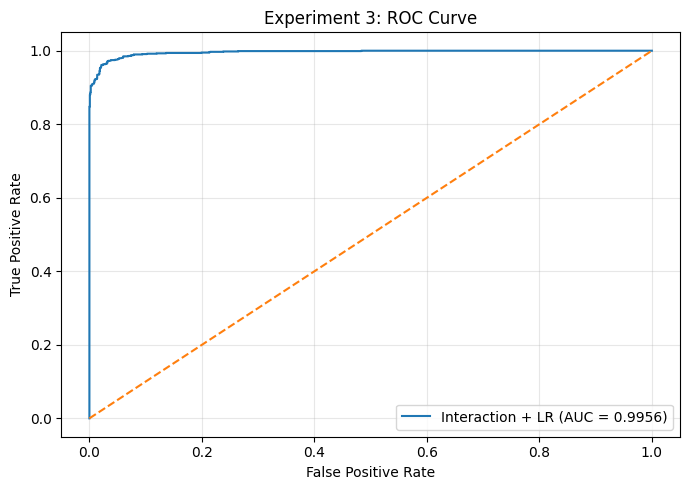

In [20]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Interaction + LR (AUC = {auc:.4f})"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Experiment 3: ROC Curve")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("Experiment3_ROC_Curve.png", dpi=300)
plt.show()

In [21]:
results = pd.DataFrame({
    "Experiment": [3],
    "Feature Representation": ["Interaction Features"],
    "Model": ["Logistic Regression"],
    "Accuracy": [accuracy],
    "Precision": [precision],
    "Recall": [recall],
    "F1-score": [f1],
    "ROC-AUC": [auc],
    "False Negative Rate": [fnr],
    "TN": [TN],
    "FP": [FP],
    "FN": [FN],
    "TP": [TP]
})

display(results)

results.to_csv(
    "Experiment3_Results.csv",
    index=False
)

,Experiment,Feature Representation,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,False Negative Rate,TN,FP,FN,TP
0,3,Interaction Features,Logistic Regression,0.970602,0.973113,0.960204,0.966615,0.995649,0.039796,1205,26,39,941
